Install Library

In [1]:
!pip -q install pandas numpy scikit-learn xgboost networkx matplotlib seaborn openpyxl

Import Libraries

In [2]:
import os
import re
import json
import math
import warnings
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd

import networkx as nx

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler

from google.colab import files

warnings.filterwarnings("ignore")

print("Libraries loaded successfully.")

Libraries loaded successfully.


Define ThreatRank Schema

In [3]:
THREATRANK_COLUMNS = [
    "scanner",
    "host",
    "asset_name",
    "asset_criticality",
    "internet_exposed",
    "service",
    "port",
    "protocol",

    "title",
    "description",
    "evidence",

    "cve",
    "cvss",
    "severity",

    "authentication_required",
    "privilege",

    "plugin_id",

    "remediation"
]

print("ThreatRank schema:")
for i, col in enumerate(THREATRANK_COLUMNS, 1):
    print(f"{i:02d}. {col}")

ThreatRank schema:
01. scanner
02. host
03. asset_name
04. asset_criticality
05. internet_exposed
06. service
07. port
08. protocol
09. title
10. description
11. evidence
12. cve
13. cvss
14. severity
15. authentication_required
16. privilege
17. plugin_id
18. remediation


Upload VA Report

In [4]:
print("Please upload your VA report.")
print("Supported formats:")
print("- CSV")
print("- JSON")
print("- XML")
print("- Nessus .nessus")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No file was uploaded.")

filename = list(uploaded.keys())[0]

print("\nUploaded file:")
print(filename)

Please upload your VA report.
Supported formats:
- CSV
- JSON
- XML
- Nessus .nessus


Saving Target_Scan_b131zv.csv to Target_Scan_b131zv.csv

Uploaded file:
Target_Scan_b131zv.csv


Detect Scanner & File Type

In [5]:
def detect_scanner(filename):
    name = filename.lower().strip()

    print("Uploaded filename:", filename)

    if name.endswith(".nessus"):
        return "Nessus"

    if name.endswith(".csv"):
        return "CSV"

    if name.endswith(".json"):
        return "JSON"

    if name.endswith(".xml"):
        return "XML"

    # Sometimes the uploaded filename doesn't have
    # a recognizable extension.
    return "Unknown"


scanner_type = detect_scanner(filename)

print("Detected type:", scanner_type)

Uploaded filename: Target_Scan_b131zv.csv
Detected type: CSV


Utility Functions

In [6]:
def clean_text(value):
    if value is None:
        return ""

    if isinstance(value, float) and np.isnan(value):
        return ""

    value = str(value)

    value = re.sub(r"\s+", " ", value)

    return value.strip()


def safe_float(value):
    try:
        if value is None:
            return np.nan

        value = str(value).strip()

        if value == "":
            return np.nan

        return float(value)

    except:
        return np.nan


def safe_int(value):
    try:
        if value is None:
            return np.nan

        return int(float(value))

    except:
        return np.nan

Nessus Parser

In [7]:
def parse_nessus(filename):

    tree = ET.parse(filename)
    root = tree.getroot()

    rows = []

    for report_host in root.findall(".//ReportHost"):

        host_name = report_host.attrib.get("name", "")

        # Try to obtain host properties
        host_properties = {}

        for tag in report_host.findall("./HostProperties/tag"):
            name = tag.attrib.get("name", "")
            value = tag.text if tag.text else ""

            host_properties[name] = value

        for item in report_host.findall("./ReportItem"):

            row = {}

            row["scanner"] = "Nessus"

            row["host"] = host_name

            row["asset_name"] = (
                host_properties.get("host-fqdn")
                or host_properties.get("netbios-name")
                or host_name
            )

            row["asset_criticality"] = 3
            row["internet_exposed"] = False

            row["service"] = item.attrib.get("svc_name", "")
            row["port"] = safe_int(item.attrib.get("port"))
            row["protocol"] = item.attrib.get("protocol", "")

            # Nessus fields
            def get_text(tag_name):
                element = item.find(tag_name)

                if element is not None and element.text:
                    return element.text.strip()

                return ""

            row["title"] = (
                get_text("plugin_name")
                or item.attrib.get("pluginName", "")
            )

            row["description"] = get_text("description")

            row["evidence"] = get_text("plugin_output")

            row["cve"] = get_text("cve")

            row["cvss"] = (
                safe_float(get_text("cvss3_base_score"))
                if get_text("cvss3_base_score")
                else safe_float(get_text("cvss_base_score"))
            )

            row["severity"] = item.attrib.get("severity", "")

            row["authentication_required"] = False

            row["privilege"] = "unknown"

            row["plugin_id"] = item.attrib.get("pluginID", "")

            row["remediation"] = get_text("solution")

            rows.append(row)

    df = pd.DataFrame(rows)

    return df

XML Parser

In [8]:
def parse_generic_xml(filename):

    tree = ET.parse(filename)

    root = tree.getroot()

    rows = []

    possible_tags = [
        "ReportItem",
        "reportitem",
        "vulnerability",
        "Vulnerability",
        "finding",
        "Finding",
        "issue",
        "Issue",
        "result",
        "Result"
    ]

    elements = []

    for tag in possible_tags:
        elements.extend(root.findall(f".//{tag}"))

    # Remove duplicates
    unique_elements = []

    seen = set()

    for element in elements:

        element_id = id(element)

        if element_id not in seen:
            unique_elements.append(element)
            seen.add(element_id)

    elements = unique_elements

    for element in elements:

        row = {}

        row["scanner"] = "XML"

        # Attributes
        for key, value in element.attrib.items():

            key_clean = key.lower().replace("-", "_").replace(" ", "_")

            if key_clean in [
                "host",
                "hostname",
                "ip",
                "ip_address"
            ]:
                row["host"] = value

            elif key_clean in [
                "port",
                "port_number"
            ]:
                row["port"] = safe_int(value)

            elif key_clean in [
                "protocol"
            ]:
                row["protocol"] = value

            elif key_clean in [
                "severity",
                "risk"
            ]:
                row["severity"] = value

            elif key_clean in [
                "pluginid",
                "plugin_id",
                "id"
            ]:
                row["plugin_id"] = value

        # Child tags
        for child in element.iter():

            if child is element:
                continue

            if child.text is None:
                continue

            key = child.tag.lower()

            value = child.text.strip()

            if key in ["title", "name", "plugin_name"]:
                row["title"] = value

            elif key in ["description", "summary", "details"]:
                row["description"] = value

            elif key in ["solution", "remediation", "recommendation"]:
                row["remediation"] = value

            elif key in ["cve", "cve_id"]:
                row["cve"] = value

            elif key in [
                "cvss",
                "cvss_score",
                "cvss_base_score",
                "cvss3_base_score"
            ]:
                row["cvss"] = safe_float(value)

            elif key in [
                "plugin_output",
                "evidence",
                "result",
                "detection"
            ]:
                row["evidence"] = value

        rows.append(row)

    return pd.DataFrame(rows)

CSV Parser

In [9]:
def parse_csv(filename):

    df = pd.read_csv(filename)

    print("Original CSV columns:")
    print(list(df.columns))

    return df

JSON Parser

In [10]:
def parse_json(filename):

    with open(filename, "r", encoding="utf-8") as f:

        data = json.load(f)

    if isinstance(data, list):

        return pd.DataFrame(data)

    if isinstance(data, dict):

        # Common cases
        for key in [
            "findings",
            "vulnerabilities",
            "results",
            "issues",
            "items"
        ]:

            if key in data and isinstance(data[key], list):

                return pd.DataFrame(data[key])

        return pd.json_normalize(data)

    raise ValueError("Unsupported JSON structure.")

Parse Uploaded Report

In [11]:
def detect_file_from_content(filename):

    with open(filename, "rb") as f:
        content = f.read(4096)

    # Remove BOM if present
    content_clean = content.lstrip(b"\xef\xbb\xbf").strip()

    # XML / Nessus
    if (
        content_clean.startswith(b"<?xml")
        or content_clean.startswith(b"<")
    ):

        try:
            text = content_clean.decode(
                "utf-8",
                errors="ignore"
            ).lower()

            if (
                "nessusclientdata" in text
                or "<reporthost" in text
                or "<reportitem" in text
            ):
                return "Nessus"

            return "XML"

        except:
            return "XML"

    # JSON
    if (
        content_clean.startswith(b"{")
        or content_clean.startswith(b"[")
    ):
        return "JSON"

    # Otherwise assume CSV/text
    return "CSV"


def parse_va_report(filename, scanner_type):

    extension = os.path.splitext(filename)[1].lower()

    # If extension is unknown, inspect file content
    if scanner_type == "Unknown":

        print(
            "File extension was not recognized."
        )

        scanner_type = detect_file_from_content(
            filename
        )

        print(
            "Detected format from file contents:",
            scanner_type
        )

    # Nessus
    if scanner_type == "Nessus":

        print("Parsing Nessus report...")

        return parse_nessus(filename)

    # CSV
    elif scanner_type == "CSV":

        print("Parsing CSV report...")

        return parse_csv(filename)

    # JSON
    elif scanner_type == "JSON":

        print("Parsing JSON report...")

        return parse_json(filename)

    # XML
    elif scanner_type == "XML":

        print("Parsing XML report...")

        return parse_generic_xml(filename)

    else:

        raise ValueError(
            f"""
Could not determine the VA report format.

Filename:
{filename}

Detected scanner:
{scanner_type}

Please upload one of:
- .nessus
- .xml
- .csv
- .json
"""
        )


df_raw = parse_va_report(
    filename,
    scanner_type
)

print(
    "\nNumber of raw findings:",
    len(df_raw)
)

display(
    df_raw.head()
)

Parsing CSV report...
Original CSV columns:
['Plugin ID', 'CVE', 'CVSS', 'Risk', 'Host', 'Protocol', 'Port', 'Name', 'Synopsis', 'Description', 'Solution', 'See Also', 'Plugin Output']

Number of raw findings: 221


,Plugin ID,CVE,CVSS,Risk,Host,Protocol,Port,Name,Synopsis,Description,Solution,See Also,Plugin Output
0,10043,CVE-1999-0103,5.0,Medium,192.168.108.15,udp,19,Chargen UDP Service Remote DoS,The remote host is running a 'chargen' service.,"When contacted, chargen responds with some ran...","- Under Unix systems, comment out the 'chargen...",http://www.nessus.org/u?f0dbdf05,NaN
1,10052,NaN,NaN,NaN,192.168.108.15,tcp,13,Daytime Service Detection,A daytime service is running on the remote host.,The remote host is running a 'daytime' service...,"- On Unix systems, comment out the 'daytime' l...",NaN,NaN
2,10052,NaN,NaN,NaN,192.168.108.15,udp,13,Daytime Service Detection,A daytime service is running on the remote host.,The remote host is running a 'daytime' service...,"- On Unix systems, comment out the 'daytime' l...",NaN,NaN
3,10061,CVE-1999-0103,NaN,NaN,192.168.108.15,tcp,7,Echo Service Detection,An echo service is running on the remote host.,The remote host is running the 'echo' service....,"- Under Unix systems, comment out the 'echo' l...",NaN,NaN
4,10061,CVE-1999-0103,NaN,NaN,192.168.108.15,udp,7,Echo Service Detection,An echo service is running on the remote host.,The remote host is running the 'echo' service....,"- Under Unix systems, comment out the 'echo' l...",NaN,NaN


Normalize Coumn Name

In [12]:
COLUMN_ALIASES = {

    "scanner": [
        "scanner",
        "scanner_name",
        "source"
    ],

    "host": [
        "host",
        "hostname",
        "ip",
        "ip_address",
        "asset"
    ],

    "asset_name": [
        "asset_name",
        "hostname",
        "host_name"
    ],

    "title": [
        "title",
        "name",
        "plugin_name",
        "vulnerability",
        "finding",
        "vulnerability_name"
    ],

    "description": [
        "description",
        "summary",
        "details"
    ],

    "evidence": [
        "evidence",
        "plugin_output",
        "result",
        "detection"
    ],

    "cve": [
        "cve",
        "cve_id",
        "cve_ids"
    ],

    "cvss": [
        "cvss",
        "cvss_score",
        "cvss_v3",
        "cvss_v3_score",
        "cvss_base_score"
    ],

    "severity": [
        "severity",
        "risk",
        "severity_level"
    ],

    "service": [
        "service",
        "service_name"
    ],

    "port": [
        "port",
        "port_number"
    ],

    "protocol": [
        "protocol"
    ],

    "remediation": [
        "solution",
        "remediation",
        "recommendation",
        "fix"
    ],

    "plugin_id": [
        "plugin_id",
        "pluginid",
        "plugin"
    ]
}

Apply Normalization

In [13]:
def normalize_column_name(column):

    return (
        str(column)
        .strip()
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
    )


def normalize_columns(df):

    df = df.copy()

    # Normalize existing names
    df.columns = [
        normalize_column_name(c)
        for c in df.columns
    ]

    rename_map = {}

    for standard_name, aliases in COLUMN_ALIASES.items():

        for alias in aliases:

            alias = normalize_column_name(alias)

            if alias in df.columns:

                rename_map[alias] = standard_name

                break

    df = df.rename(columns=rename_map)

    return df

Complete Missinf Columns

In [14]:
def complete_schema(df):

    df = df.copy()

    for column in THREATRANK_COLUMNS:

        if column not in df.columns:

            if column == "asset_criticality":

                df[column] = 3

            elif column == "internet_exposed":

                df[column] = False

            elif column == "authentication_required":

                df[column] = False

            else:

                df[column] = ""

    return df[THREATRANK_COLUMNS]

Clean & Normalize Report

In [15]:
df = normalize_columns(df_raw)

df = complete_schema(df)

# Text fields
text_columns = [
    "scanner",
    "host",
    "asset_name",
    "service",
    "protocol",
    "title",
    "description",
    "evidence",
    "cve",
    "severity",
    "privilege",
    "plugin_id",
    "remediation"
]

for column in text_columns:

    df[column] = df[column].apply(clean_text)


# Numeric fields
df["port"] = df["port"].apply(safe_int)

df["cvss"] = df["cvss"].apply(safe_float)

df["asset_criticality"] = (
    df["asset_criticality"]
    .apply(safe_float)
    .fillna(3)
)


# Convert boolean-like values
def to_bool(value):

    value = str(value).lower().strip()

    return value in [
        "true",
        "yes",
        "1",
        "y",
        "external",
        "internet"
    ]


df["internet_exposed"] = df["internet_exposed"].apply(to_bool)

df["authentication_required"] = (
    df["authentication_required"]
    .apply(to_bool)
)


# If scanner wasn't provided
df.loc[
    df["scanner"] == "",
    "scanner"
] = scanner_type


# Whether CVE exists
df["has_cve"] = (
    df["cve"]
    .str.contains(r"CVE-\d{4}-\d+", case=False, na=False)
)


# Create combined text
df["finding_text"] = (
    df["title"].fillna("")
    + " "
    + df["description"].fillna("")
    + " "
    + df["evidence"].fillna("")
)

print("Normalized findings:", len(df))

display(df.head())

Normalized findings: 221


,scanner,host,asset_name,asset_criticality,internet_exposed,service,port,protocol,title,description,evidence,cve,cvss,severity,authentication_required,privilege,plugin_id,remediation,has_cve,finding_text
0,CSV,192.168.108.15,,3.0,False,,19,udp,Chargen UDP Service Remote DoS,"When contacted, chargen responds with some ran...",,CVE-1999-0103,5.0,Medium,False,,10043,"- Under Unix systems, comment out the 'chargen...",True,"Chargen UDP Service Remote DoS When contacted,..."
1,CSV,192.168.108.15,,3.0,False,,13,tcp,Daytime Service Detection,The remote host is running a 'daytime' service...,,,NaN,,False,,10052,"- On Unix systems, comment out the 'daytime' l...",False,Daytime Service Detection The remote host is r...
2,CSV,192.168.108.15,,3.0,False,,13,udp,Daytime Service Detection,The remote host is running a 'daytime' service...,,,NaN,,False,,10052,"- On Unix systems, comment out the 'daytime' l...",False,Daytime Service Detection The remote host is r...
3,CSV,192.168.108.15,,3.0,False,,7,tcp,Echo Service Detection,The remote host is running the 'echo' service....,,CVE-1999-0103,NaN,,False,,10061,"- Under Unix systems, comment out the 'echo' l...",True,Echo Service Detection The remote host is runn...
4,CSV,192.168.108.15,,3.0,False,,7,udp,Echo Service Detection,The remote host is running the 'echo' service....,,CVE-1999-0103,NaN,,False,,10061,"- Under Unix systems, comment out the 'echo' l...",True,Echo Service Detection The remote host is runn...


Check Uploaded Data

In [16]:
print("========== ThreatRank Input Summary ==========")

print("Total findings:", len(df))

print(
    "Findings with CVE:",
    int(df["has_cve"].sum())
)

print(
    "Findings without CVE:",
    int((~df["has_cve"]).sum())
)

print(
    "Unique hosts:",
    df["host"].nunique()
)

print(
    "Unique services:",
    df["service"].nunique()
)

print(
    "Unique ports:",
    df["port"].nunique()
)

print("\nSeverity distribution:")
display(
    df["severity"]
    .value_counts(dropna=False)
    .to_frame("count")
)

========== ThreatRank Input Summary ==========
Total findings: 221
Findings with CVE: 52
Findings without CVE: 169
Unique hosts: 1
Unique services: 1
Unique ports: 37

Severity distribution:


,count
severity,
,154
Medium,33
Critical,22
Low,12


Create Similarity Function

In [17]:
def text_similarity(text1, text2):

    if not text1 or not text2:
        return 0

    vectorizer = TfidfVectorizer(
        stop_words="english"
    )

    try:

        matrix = vectorizer.fit_transform(
            [text1, text2]
        )

        similarity = cosine_similarity(
            matrix[0:1],
            matrix[1:2]
        )[0][0]

        return float(similarity)

    except:

        return 0

Correlation Logic

In [18]:
def calculate_correlation_score(row1, row2):

    score = 0

    # Same host
    if (
        row1["host"] != ""
        and row1["host"] == row2["host"]
    ):
        score += 0.25

    # Same service
    if (
        row1["service"] != ""
        and row1["service"] == row2["service"]
    ):
        score += 0.10

    # Same port
    if (
        not pd.isna(row1["port"])
        and not pd.isna(row2["port"])
        and row1["port"] == row2["port"]
    ):
        score += 0.10

    # Same CVE
    if (
        row1["cve"] != ""
        and row1["cve"] == row2["cve"]
    ):
        score += 0.35

    # Same plugin
    if (
        row1["plugin_id"] != ""
        and row1["plugin_id"] == row2["plugin_id"]
    ):
        score += 0.10

    # Text similarity
    similarity = text_similarity(
        row1["finding_text"],
        row2["finding_text"]
    )

    score += 0.20 * similarity

    return min(score, 1.0)

Correlation Finding

In [19]:
def correlate_findings(df, threshold=0.65):

    df = df.copy()

    n = len(df)

    parent = list(range(n))

    def find(x):

        while parent[x] != x:

            parent[x] = parent[parent[x]]

            x = parent[x]

        return x

    def union(a, b):

        root_a = find(a)
        root_b = find(b)

        if root_a != root_b:

            parent[root_b] = root_a

    for i in range(n):

        for j in range(i + 1, n):

            score = calculate_correlation_score(
                df.iloc[i],
                df.iloc[j]
            )

            if score >= threshold:

                union(i, j)

    groups = {}

    for i in range(n):

        root = find(i)

        groups.setdefault(root, [])

        groups[root].append(i)

    canonical_id = {}

    counter = 1

    for root, indices in groups.items():

        cid = f"F-{counter:04d}"

        for index in indices:

            canonical_id[index] = cid

        counter += 1

    df["canonical_id"] = [
        canonical_id[i]
        for i in range(n)
    ]

    return df


df_corr = correlate_findings(df)

print(
    "Raw observations:",
    len(df_corr)
)

print(
    "Canonical findings:",
    df_corr["canonical_id"].nunique()
)

display(
    df_corr[
        [
            "canonical_id",
            "host",
            "title",
            "cve"
        ]
    ].head(20)
)

Raw observations: 221
Canonical findings: 183


,canonical_id,host,title,cve
0,F-0001,192.168.108.15,Chargen UDP Service Remote DoS,CVE-1999-0103
1,F-0002,192.168.108.15,Daytime Service Detection,
2,F-0003,192.168.108.15,Daytime Service Detection,
3,F-0004,192.168.108.15,Echo Service Detection,CVE-1999-0103
4,F-0004,192.168.108.15,Echo Service Detection,CVE-1999-0103
5,F-0004,192.168.108.15,Echo Service Detection,CVE-1999-0635
6,F-0004,192.168.108.15,Echo Service Detection,CVE-1999-0635
7,F-0005,192.168.108.15,Finger Recursive Request Arbitrary Site Redire...,CVE-1999-0105
8,F-0006,192.168.108.15,Finger Recursive Request Arbitrary Site Redire...,CVE-1999-0106
9,F-0007,192.168.108.15,FTP Server Detection,


Create Canonical Findings

In [20]:
def create_canonical_findings(df):

    canonical = []

    for cid, group in df.groupby("canonical_id"):

        first = group.iloc[0]

        canonical.append({

            "canonical_id": cid,

            "host": first["host"],

            "asset_name": first["asset_name"],

            "asset_criticality": group[
                "asset_criticality"
            ].max(),

            "internet_exposed": group[
                "internet_exposed"
            ].max(),

            "service": first["service"],

            "port": first["port"],

            "protocol": first["protocol"],

            "title": first["title"],

            "description": first["description"],

            "evidence": " | ".join(
                group["evidence"]
                .dropna()
                .astype(str)
                .unique()
            ),

            "cve": " | ".join(
                group["cve"]
                .dropna()
                .astype(str)
                .unique()
            ),

            "cvss": group["cvss"].max(),

            "severity": first["severity"],

            "authentication_required":
                group["authentication_required"].max(),

            "privilege":
                first["privilege"],

            "plugin_id":
                " | ".join(
                    group["plugin_id"]
                    .dropna()
                    .astype(str)
                    .unique()
                ),

            "remediation":
                first["remediation"],

            "scanner_count":
                group["scanner"].nunique(),

            "observation_count":
                len(group)
        })

    return pd.DataFrame(canonical)


canonical_df = create_canonical_findings(df_corr)

print(
    "Canonical findings:",
    len(canonical_df)
)

display(canonical_df.head())

Canonical findings: 183


,canonical_id,host,asset_name,asset_criticality,internet_exposed,service,port,protocol,title,description,evidence,cve,cvss,severity,authentication_required,privilege,plugin_id,remediation,scanner_count,observation_count
0,F-0001,192.168.108.15,,3.0,False,,19,udp,Chargen UDP Service Remote DoS,"When contacted, chargen responds with some ran...",,CVE-1999-0103,5.0,Medium,False,,10043,"- Under Unix systems, comment out the 'chargen...",1,1
1,F-0002,192.168.108.15,,3.0,False,,13,tcp,Daytime Service Detection,The remote host is running a 'daytime' service...,,,NaN,,False,,10052,"- On Unix systems, comment out the 'daytime' l...",1,1
2,F-0003,192.168.108.15,,3.0,False,,13,udp,Daytime Service Detection,The remote host is running a 'daytime' service...,,,NaN,,False,,10052,"- On Unix systems, comment out the 'daytime' l...",1,1
3,F-0004,192.168.108.15,,3.0,False,,7,tcp,Echo Service Detection,The remote host is running the 'echo' service....,,CVE-1999-0103 | CVE-1999-0635,NaN,,False,,10061,"- Under Unix systems, comment out the 'echo' l...",1,4
4,F-0005,192.168.108.15,,3.0,False,,79,tcp,Finger Recursive Request Arbitrary Site Redire...,The remote finger service accepts redirect req...,,CVE-1999-0105,5.0,Medium,False,,10073,Disable the remote finger daemon (comment out ...,1,1


CWE Training Data

In [21]:
cwe_training = pd.DataFrame({

    "text": [

        "SQL injection database query user input",

        "blind SQL injection vulnerable parameter",

        "cross site scripting XSS javascript input",

        "stored XSS malicious script browser",

        "command injection operating system command",

        "remote command execution shell command",

        "path traversal directory traversal file",

        "directory traversal arbitrary file read",

        "weak password authentication credentials",

        "default password authentication",

        "outdated TLS weak encryption",

        "weak cryptographic algorithm",

        "buffer overflow memory corruption",

        "stack buffer overflow",

        "privilege escalation insufficient permissions"

    ],

    "cwe": [

        "CWE-89",
        "CWE-89",

        "CWE-79",
        "CWE-79",

        "CWE-78",
        "CWE-78",

        "CWE-22",
        "CWE-22",

        "CWE-521",
        "CWE-521",

        "CWE-327",
        "CWE-327",

        "CWE-120",
        "CWE-120",

        "CWE-269"
    ]
})


vectorizer_cwe = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

X_cwe = vectorizer_cwe.fit_transform(
    cwe_training["text"]
)

cwe_model = LogisticRegression(
    max_iter=1000
)

cwe_model.fit(
    X_cwe,
    cwe_training["cwe"]
)

print("CWE classifier trained.")

CWE classifier trained.


Predict CWE

In [22]:
def predict_cwe(text):

    if not text:

        return "CWE-Unknown"

    X = vectorizer_cwe.transform([text])

    prediction = cwe_model.predict(X)[0]

    return prediction

Apply CWE Classification

In [23]:
canonical_df["finding_text"] = (
    canonical_df["title"].fillna("")
    + " "
    + canonical_df["description"].fillna("")
    + " "
    + canonical_df["evidence"].fillna("")
)

canonical_df["cwe"] = (
    canonical_df["finding_text"]
    .apply(predict_cwe)
)

display(
    canonical_df[
        [
            "canonical_id",
            "title",
            "cwe"
        ]
    ].head(20)
)

,canonical_id,title,cwe
0,F-0001,Chargen UDP Service Remote DoS,CWE-78
1,F-0002,Daytime Service Detection,CWE-78
2,F-0003,Daytime Service Detection,CWE-78
3,F-0004,Echo Service Detection,CWE-78
4,F-0005,Finger Recursive Request Arbitrary Site Redire...,CWE-78
5,F-0006,Finger Recursive Request Arbitrary Site Redire...,CWE-78
6,F-0007,FTP Server Detection,CWE-78
7,F-0008,HTTP Server Type and Version,CWE-78
8,F-0009,HTTP Server Type and Version,CWE-78
9,F-0010,HTTP Server Type and Version,CWE-78


Demo Likelihood Data

In [24]:
likelihood_training = pd.DataFrame({

    "cvss": [
        2.0, 3.0, 4.0, 5.0,
        6.0, 7.0, 8.0, 9.0,
        10.0, 8.5, 6.5, 4.5,
        9.5, 7.5, 5.5
    ],

    "has_cve": [
        0, 0, 1, 1,
        1, 1, 1, 1,
        1, 1, 1, 1,
        1, 1, 1
    ],

    "internet_exposed": [
        0, 0, 0, 0,
        0, 1, 1, 1,
        1, 1, 0, 0,
        1, 1, 0
    ],

    "likelihood": [
        0.10, 0.15, 0.20, 0.30,
        0.40, 0.55, 0.70, 0.85,
        0.95, 0.80, 0.45, 0.25,
        0.92, 0.65, 0.35
    ]
})


X_likelihood = likelihood_training[
    [
        "cvss",
        "has_cve",
        "internet_exposed"
    ]
]

y_likelihood = likelihood_training[
    "likelihood"
]

likelihood_model = GradientBoostingRegressor(
    random_state=42
)

likelihood_model.fit(
    X_likelihood,
    y_likelihood
)

print("Likelihood model trained.")

Likelihood model trained.


Predic Likelihood

In [25]:
def predict_likelihood(row):

    cvss = row["cvss"]

    if pd.isna(cvss):

        cvss = 5.0

    features = pd.DataFrame([{

        "cvss": cvss,

        "has_cve":
            int(
                bool(
                    re.search(
                        r"CVE-\d{4}-\d+",
                        str(row["cve"])
                    )
                )
            ),

        "internet_exposed":
            int(bool(row["internet_exposed"]))
    }])

    prediction = likelihood_model.predict(
        features
    )[0]

    return float(
        np.clip(
            prediction,
            0,
            1
        )
    )

Calculate *L*

In [26]:
canonical_df["likelihood"] = (
    canonical_df
    .apply(predict_likelihood, axis=1)
)

canonical_df[
    [
        "canonical_id",
        "title",
        "likelihood"
    ]
].head(20)

,canonical_id,title,likelihood
0,F-0001,Chargen UDP Service Remote DoS,0.300006
1,F-0002,Daytime Service Detection,0.291078
2,F-0003,Daytime Service Detection,0.291078
3,F-0004,Echo Service Detection,0.300006
4,F-0005,Finger Recursive Request Arbitrary Site Redire...,0.300006
5,F-0006,Finger Recursive Request Arbitrary Site Redire...,0.300006
6,F-0007,FTP Server Detection,0.291078
7,F-0008,HTTP Server Type and Version,0.291078
8,F-0009,HTTP Server Type and Version,0.291078
9,F-0010,HTTP Server Type and Version,0.291078


Build Attack Graph

In [27]:
def build_attack_graph(df):

    G = nx.DiGraph()

    for _, row in df.iterrows():

        finding_id = row["canonical_id"]

        host = row["host"]

        asset = row["asset_name"]

        service = row["service"]

        port = row["port"]

        # External node
        if row["internet_exposed"]:

            external_node = "Internet"

            G.add_node(
                external_node,
                type="external"
            )

            G.add_edge(
                external_node,
                finding_id,
                relationship="exposes"
            )

        # Asset node
        asset_node = f"Asset:{host}"

        G.add_node(
            asset_node,
            type="asset",
            criticality=row["asset_criticality"]
        )

        G.add_edge(
            finding_id,
            asset_node,
            relationship="affects"
        )

        # Service node
        if service or not pd.isna(port):

            service_node = (
                f"Service:{host}:"
                f"{service}:"
                f"{port}"
            )

            G.add_node(
                service_node,
                type="service"
            )

            G.add_edge(
                service_node,
                finding_id,
                relationship="contains"
            )

    return G


G = build_attack_graph(canonical_df)

print("Attack graph nodes:", G.number_of_nodes())

print("Attack graph edges:", G.number_of_edges())

Attack graph nodes: 221
Attack graph edges: 366


Visualize Attack Graph

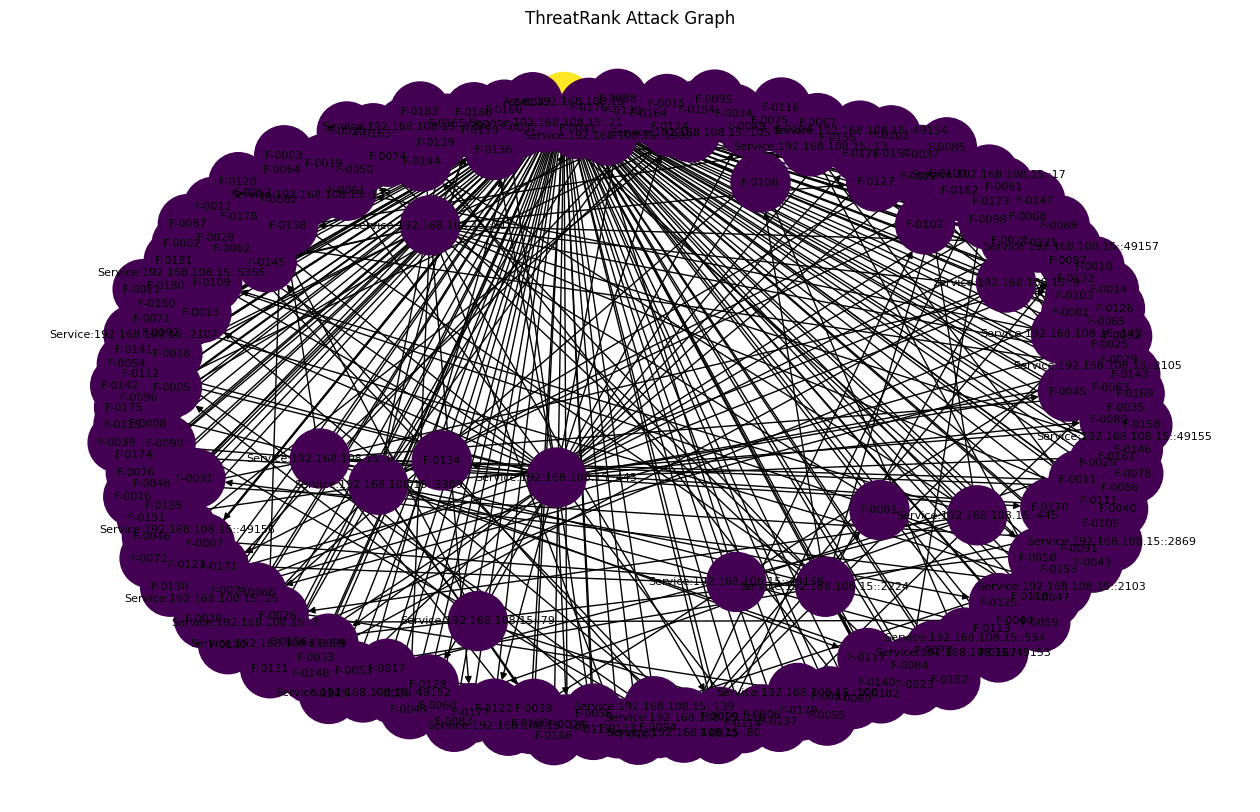

In [28]:
plt.figure(figsize=(16, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    k=1.5
)

node_colors = []

for node in G.nodes:

    node_type = G.nodes[node].get(
        "type",
        ""
    )

    if node_type == "external":

        node_colors.append(0.9)

    elif node_type == "asset":

        node_colors.append(0.5)

    else:

        node_colors.append(0.2)


nx.draw_networkx(
    G,
    pos,
    node_color=node_colors,
    cmap="viridis",
    node_size=1800,
    font_size=8,
    arrows=True
)

plt.title(
    "ThreatRank Attack Graph"
)

plt.axis("off")

plt.show()

Consequence Function

In [29]:
def calculate_consequence(row):

    # Base consequence from asset criticality
    criticality = (
        row["asset_criticality"]
        if not pd.isna(
            row["asset_criticality"]
        )
        else 3
    )

    # Convert 1-5 criticality to 0-1
    consequence = criticality / 5.0

    # Internet exposure
    if row["internet_exposed"]:

        consequence += 0.15

    # High CVSS can increase potential impact
    if not pd.isna(row["cvss"]):

        consequence += (
            (row["cvss"] / 10.0) * 0.20
        )

    # Privilege considerations
    privilege = str(
        row["privilege"]
    ).lower()

    if privilege in [
        "root",
        "administrator",
        "admin",
        "system"
    ]:

        consequence += 0.15

    return float(
        np.clip(
            consequence,
            0,
            1
        )
    )

Calculate *C*

In [30]:
canonical_df["consequence"] = (
    canonical_df
    .apply(
        calculate_consequence,
        axis=1
    )
)

display(
    canonical_df[
        [
            "canonical_id",
            "title",
            "consequence"
        ]
    ].head(20)
)

,canonical_id,title,consequence
0,F-0001,Chargen UDP Service Remote DoS,0.7
1,F-0002,Daytime Service Detection,0.6
2,F-0003,Daytime Service Detection,0.6
3,F-0004,Echo Service Detection,0.6
4,F-0005,Finger Recursive Request Arbitrary Site Redire...,0.7
5,F-0006,Finger Recursive Request Arbitrary Site Redire...,0.7
6,F-0007,FTP Server Detection,0.6
7,F-0008,HTTP Server Type and Version,0.6
8,F-0009,HTTP Server Type and Version,0.6
9,F-0010,HTTP Server Type and Version,0.6


Calculate Risk

*R = L x C*

In [31]:
canonical_df["risk_score"] = (
    canonical_df["likelihood"]
    *
    canonical_df["consequence"]
)

Risk Category

In [32]:
def risk_category(score):

    if score >= 0.75:

        return "Critical"

    elif score >= 0.50:

        return "High"

    elif score >= 0.25:

        return "Medium"

    else:

        return "Low"


canonical_df["risk_category"] = (
    canonical_df["risk_score"]
    .apply(risk_category)
)

Priority Ranking

In [33]:
priority_df = canonical_df.sort_values(
    by="risk_score",
    ascending=False
).reset_index(drop=True)

priority_df["priority"] = (
    np.arange(len(priority_df)) + 1
)

priority_df = priority_df[
    [
        "priority",
        "canonical_id",
        "risk_category",
        "risk_score",
        "likelihood",
        "consequence",
        "cwe",
        "cve",
        "cvss",
        "severity",
        "host",
        "service",
        "port",
        "title",
        "remediation",
        "scanner_count",
        "observation_count"
    ]
]

display(priority_df.head(20))

,priority,canonical_id,risk_category,risk_score,likelihood,consequence,cwe,cve,cvss,severity,host,service,port,title,remediation,scanner_count,observation_count
0,1,F-0183,High,0.625066,0.781332,0.800,CWE-521,CVE-2016-2183 | CVE-2016-2177 | CVE-2016-2178 ...,10.0,Low,192.168.108.15,,81,OpenSSL < 1.1.0 Default Weak 64-bit Block Ciph...,"Upgrade to OpenSSL version 1.1.0 or later, and...",1,28
1,2,F-0176,Medium,0.376084,0.510983,0.736,CWE-521,CVE-2016-0128,6.8,Medium,192.168.108.15,,49158,MS16-047: Security Update for SAM and LSAD Rem...,Microsoft has released a set of patches for Wi...,1,1
2,3,F-0151,Medium,0.327600,0.450000,0.728,CWE-78,,6.4,Medium,192.168.108.15,,3389,SSL Certificate Cannot Be Trusted,Purchase or generate a proper certificate for ...,1,1
3,4,F-0150,Medium,0.327600,0.450000,0.728,CWE-78,,6.4,Medium,192.168.108.15,,443,SSL Certificate Cannot Be Trusted,Purchase or generate a proper certificate for ...,1,1
4,5,F-0162,Medium,0.327600,0.450000,0.728,CWE-78,,6.4,Medium,192.168.108.15,,3389,SSL Self-Signed Certificate,Purchase or generate a proper certificate for ...,1,1
5,6,F-0161,Medium,0.327600,0.450000,0.728,CWE-78,,6.4,Medium,192.168.108.15,,443,SSL Self-Signed Certificate,Purchase or generate a proper certificate for ...,1,1
6,7,F-0085,Low,0.210604,0.300006,0.702,CWE-521,CVE-2005-1794,5.1,Medium,192.168.108.15,,3389,Microsoft Windows Remote Desktop Protocol Serv...,- Force the use of SSL as a transport layer fo...,1,1
7,8,F-0129,Low,0.210004,0.300006,0.700,CWE-78,CVE-2009-0884,5.0,Medium,192.168.108.15,,21,FileZilla Server < 0.9.31 Denial of Service,Upgrade to FileZilla Server version 0.9.31 or ...,1,1
8,9,F-0001,Low,0.210004,0.300006,0.700,CWE-78,CVE-1999-0103,5.0,Medium,192.168.108.15,,19,Chargen UDP Service Remote DoS,"- Under Unix systems, comment out the 'chargen...",1,1
9,10,F-0006,Low,0.210004,0.300006,0.700,CWE-78,CVE-1999-0106,5.0,Medium,192.168.108.15,,79,Finger Recursive Request Arbitrary Site Redire...,Disable the remote finger daemon (comment out ...,1,1


Group Remediation

In [34]:
def create_remediation_summary(df):

    remediation = (
        df.groupby("remediation")
        .agg(
            finding_count=(
                "canonical_id",
                "count"
            ),

            total_risk=(
                "risk_score",
                "sum"
            ),

            average_risk=(
                "risk_score",
                "mean"
            )
        )
        .reset_index()
    )

    remediation = remediation.sort_values(
        "total_risk",
        ascending=False
    )

    return remediation


remediation_df = create_remediation_summary(
    canonical_df
)

display(remediation_df.head(20))

,remediation,finding_count,total_risk,average_risk
0,,90,15.718194,0.174647
35,Protect your target with an IP filter.,26,4.540811,0.174647
36,Purchase or generate a proper certificate for ...,5,1.514155,0.302831
43,Set a properly configured Content-Security-Pol...,4,0.698586,0.174647
44,Set a properly configured X-Frame-Options head...,4,0.698586,0.174647
46,"Upgrade to OpenSSL version 1.1.0 or later, and...",1,0.625066,0.625066
41,Rescan with a longer network timeout or less p...,3,0.523940,0.174647
16,Disable the remote finger daemon (comment out ...,2,0.420008,0.210004
30,Make sure that browsable directories do not le...,2,0.407509,0.203754
26,"If required, update Apache's configuration fil...",2,0.407509,0.203754


Readable Recommendation

In [35]:
def generate_recommendation(row):

    recommendations = []

    risk = row["risk_category"]

    title = row["title"]

    remediation = row["remediation"]

    if risk in ["Critical", "High"]:

        recommendations.append(
            "Prioritize remediation immediately."
        )

    elif risk == "Medium":

        recommendations.append(
            "Schedule remediation according to risk."
        )

    else:

        recommendations.append(
            "Monitor and remediate according to maintenance schedule."
        )

    if remediation:

        recommendations.append(
            f"Recommended action: {remediation}"
        )

    if row["internet_exposed"]:

        recommendations.append(
            "Review Internet exposure and external reachability."
        )

    if row["cve"]:

        recommendations.append(
            f"Investigate associated CVE(s): {row['cve']}"
        )

    return " ".join(recommendations)


canonical_df["recommendation"] = (
    canonical_df.apply(
        generate_recommendation,
        axis=1
    )
)

display(
    canonical_df[
        [
            "canonical_id",
            "risk_category",
            "recommendation"
        ]
    ].head(20)
)

,canonical_id,risk_category,recommendation
0,F-0001,Low,Monitor and remediate according to maintenance...
1,F-0002,Low,Monitor and remediate according to maintenance...
2,F-0003,Low,Monitor and remediate according to maintenance...
3,F-0004,Low,Monitor and remediate according to maintenance...
4,F-0005,Low,Monitor and remediate according to maintenance...
5,F-0006,Low,Monitor and remediate according to maintenance...
6,F-0007,Low,Monitor and remediate according to maintenance...
7,F-0008,Low,Monitor and remediate according to maintenance...
8,F-0009,Low,Monitor and remediate according to maintenance...
9,F-0010,Low,Monitor and remediate according to maintenance...


Final Report

In [36]:
final_report = canonical_df.sort_values(
    "risk_score",
    ascending=False
).reset_index(drop=True)

final_report["priority"] = (
    np.arange(len(final_report)) + 1
)

final_report = final_report[
    [
        "priority",
        "canonical_id",

        "risk_category",
        "risk_score",

        "likelihood",
        "consequence",

        "cwe",
        "cve",
        "cvss",

        "severity",

        "host",
        "asset_name",
        "asset_criticality",
        "internet_exposed",

        "service",
        "port",
        "protocol",

        "title",
        "description",
        "evidence",

        "remediation",
        "recommendation",

        "scanner_count",
        "observation_count"
    ]
]

display(final_report.head(20))

,priority,canonical_id,risk_category,risk_score,likelihood,consequence,cwe,cve,cvss,severity,...,service,port,protocol,title,description,evidence,remediation,recommendation,scanner_count,observation_count
0,1,F-0183,High,0.625066,0.781332,0.800,CWE-521,CVE-2016-2183 | CVE-2016-2177 | CVE-2016-2178 ...,10.0,Low,...,,81,tcp,OpenSSL < 1.1.0 Default Weak 64-bit Block Ciph...,"According to its banner, the version of OpenSS...",Banner : Apache/2.4.23 (Win32) OpenSSL/1.0.2h ...,"Upgrade to OpenSSL version 1.1.0 or later, and...",Prioritize remediation immediately. Recommende...,1,28
1,2,F-0176,Medium,0.376084,0.510983,0.736,CWE-521,CVE-2016-0128,6.8,Medium,...,,49158,tcp,MS16-047: Security Update for SAM and LSAD Rem...,The remote Windows host is affected by an elev...,,Microsoft has released a set of patches for Wi...,Schedule remediation according to risk. Recomm...,1,1
2,3,F-0151,Medium,0.327600,0.450000,0.728,CWE-78,,6.4,Medium,...,,3389,tcp,SSL Certificate Cannot Be Trusted,The server's X.509 certificate does not have a...,The following certificate was at the top of th...,Purchase or generate a proper certificate for ...,Schedule remediation according to risk. Recomm...,1,1
3,4,F-0150,Medium,0.327600,0.450000,0.728,CWE-78,,6.4,Medium,...,,443,tcp,SSL Certificate Cannot Be Trusted,The server's X.509 certificate does not have a...,The following certificate was at the top of th...,Purchase or generate a proper certificate for ...,Schedule remediation according to risk. Recomm...,1,1
4,5,F-0162,Medium,0.327600,0.450000,0.728,CWE-78,,6.4,Medium,...,,3389,tcp,SSL Self-Signed Certificate,The X.509 certificate chain for this service i...,The following certificate was found at the top...,Purchase or generate a proper certificate for ...,Schedule remediation according to risk. Recomm...,1,1
5,6,F-0161,Medium,0.327600,0.450000,0.728,CWE-78,,6.4,Medium,...,,443,tcp,SSL Self-Signed Certificate,The X.509 certificate chain for this service i...,The following certificate was found at the top...,Purchase or generate a proper certificate for ...,Schedule remediation according to risk. Recomm...,1,1
6,7,F-0085,Low,0.210604,0.300006,0.702,CWE-521,CVE-2005-1794,5.1,Medium,...,,3389,tcp,Microsoft Windows Remote Desktop Protocol Serv...,The remote version of the Remote Desktop Proto...,,- Force the use of SSL as a transport layer fo...,Monitor and remediate according to maintenance...,1,1
7,8,F-0129,Low,0.210004,0.300006,0.700,CWE-78,CVE-2009-0884,5.0,Medium,...,,21,tcp,FileZilla Server < 0.9.31 Denial of Service,"According to its banner, the version of FileZi...",The remote FileZilla server returned the follo...,Upgrade to FileZilla Server version 0.9.31 or ...,Monitor and remediate according to maintenance...,1,1
8,9,F-0001,Low,0.210004,0.300006,0.700,CWE-78,CVE-1999-0103,5.0,Medium,...,,19,udp,Chargen UDP Service Remote DoS,"When contacted, chargen responds with some ran...",,"- Under Unix systems, comment out the 'chargen...",Monitor and remediate according to maintenance...,1,1
9,10,F-0006,Low,0.210004,0.300006,0.700,CWE-78,CVE-1999-0106,5.0,Medium,...,,79,tcp,Finger Recursive Request Arbitrary Site Redire...,The remote finger service accepts redirect req...,,Disable the remote finger daemon (comment out ...,Monitor and remediate according to maintenance...,1,1


Risk Distrubution

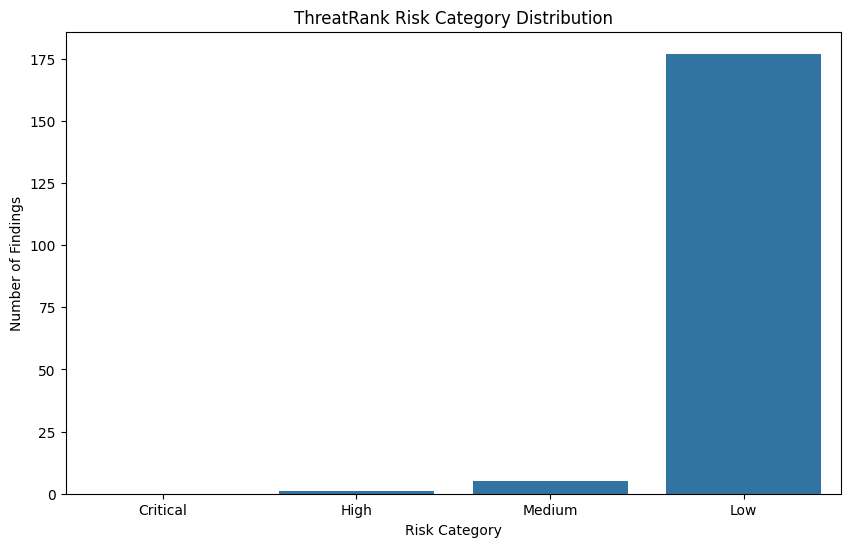

In [37]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=final_report,
    x="risk_category",
    order=[
        "Critical",
        "High",
        "Medium",
        "Low"
    ]
)

plt.title(
    "ThreatRank Risk Category Distribution"
)

plt.xlabel("Risk Category")

plt.ylabel("Number of Findings")

plt.show()

Risk Score Visualization

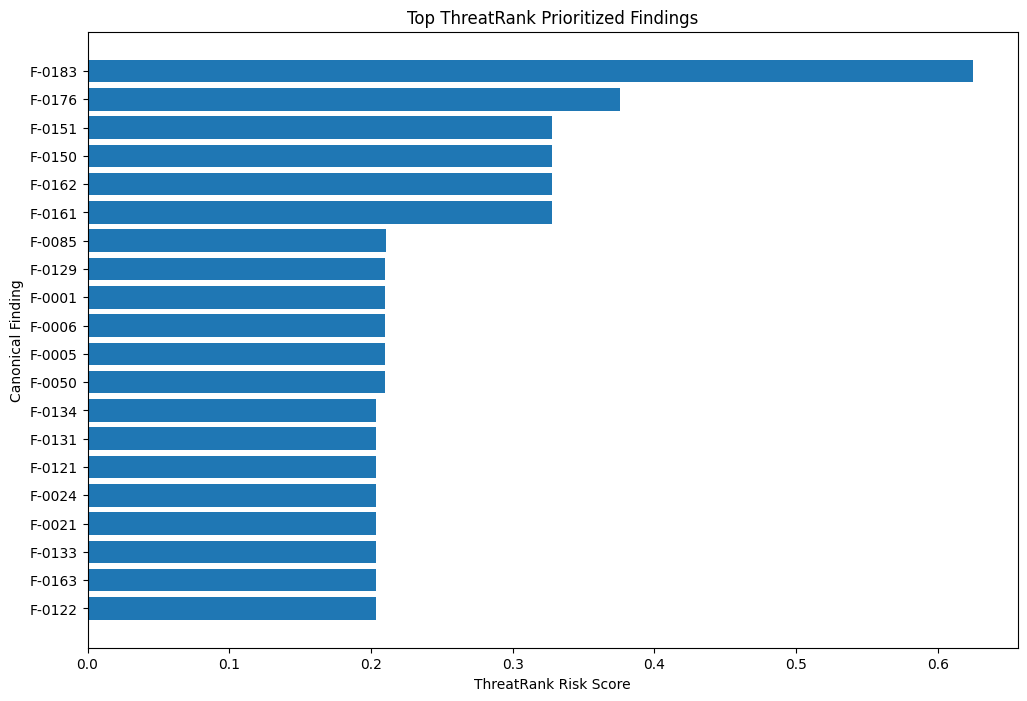

In [38]:
plot_df = final_report.head(20).copy()

plt.figure(figsize=(12, 8))

plt.barh(
    plot_df["canonical_id"],
    plot_df["risk_score"]
)

plt.xlabel("ThreatRank Risk Score")

plt.ylabel("Canonical Finding")

plt.title(
    "Top ThreatRank Prioritized Findings"
)

plt.gca().invert_yaxis()

plt.show()

Likelihood vs Consequence

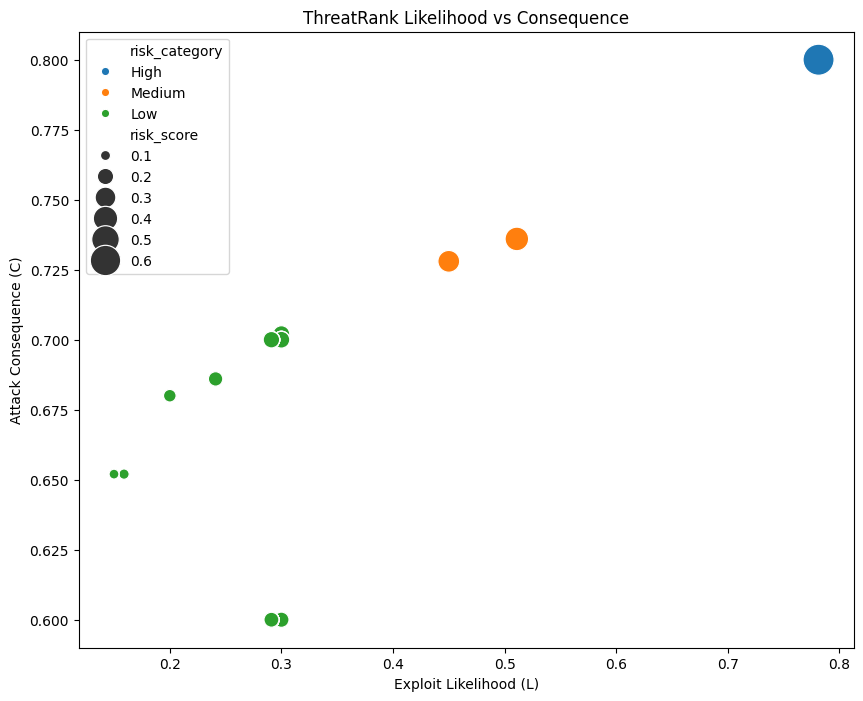

In [39]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=final_report,
    x="likelihood",
    y="consequence",
    size="risk_score",
    hue="risk_category",
    sizes=(50, 500)
)

plt.title(
    "ThreatRank Likelihood vs Consequence"
)

plt.xlabel("Exploit Likelihood (L)")

plt.ylabel("Attack Consequence (C)")

plt.show()

Export ThreatRank Report File

In [40]:
final_report.to_csv(
    "ThreatRank_Final_Report.csv",
    index=False
)

final_report.to_excel(
    "ThreatRank_Final_Report.xlsx",
    index=False
)

canonical_df.to_csv(
    "ThreatRank_Canonical_Findings.csv",
    index=False
)

print("Files created:")
print("- ThreatRank_Final_Report.csv")
print("- ThreatRank_Final_Report.xlsx")
print("- ThreatRank_Canonical_Findings.csv")

Files created:
- ThreatRank_Final_Report.csv
- ThreatRank_Final_Report.xlsx
- ThreatRank_Canonical_Findings.csv


Download ThreatRank Report File

In [41]:
files.download(
    "ThreatRank_Final_Report.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download Attack Graph

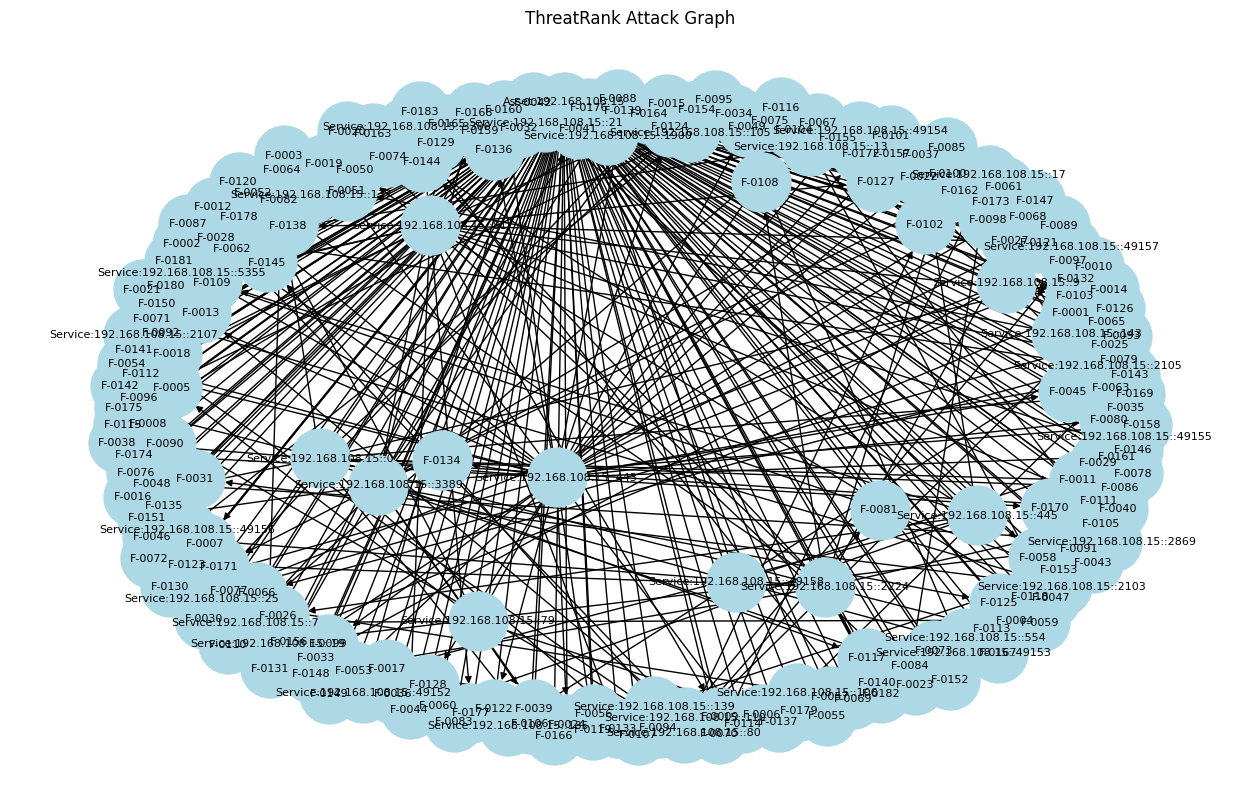

In [42]:
plt.figure(figsize=(16, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    k=1.5
)

nx.draw_networkx(
    G,
    pos,
    node_color="lightblue",
    node_size=1800,
    font_size=8,
    arrows=True
)

plt.title("ThreatRank Attack Graph")

plt.axis("off")

plt.savefig(
    "ThreatRank_Attack_Graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()